# DS3000 Project: University Dropout and Academic Success

**Group:** 03
**Dataset:** University Dropout and Academic Success, [OpenML 46960](https://www.openml.org/d/46960) (3-class classification: Dropout, Enrolled, Graduate)
**Members:** Marcellus Remani, Pavle, Stephen, Aryan

## Decisions

| ID | Decision | Value |
|---|---|---|
| D1 | Target definition | Keep all three classes (Dropout, Enrolled, Graduate). A prediction means the student's outcome at the end of the normal course duration. |
| D2 | Prediction timing | Predict from information available by the end of year 1. The curricular-unit features describe the 1st and 2nd semesters. |
| D3 | Primary metric | Macro-F1, reported with accuracy, balanced accuracy, and per-class precision and recall. Recall on Dropout is the most operationally important number. |
| D4 | Split | Stratified 60/20/20 train/validation/test, SEED = 42, split indices saved to artifacts/splits/ and reloaded by every later cell. |
| D5 | Test-set policy | All choices are made on validation only. Test metrics are computed once, in one labelled cell, and never used for decisions. (To confirm with the TA whether Stage 1 shows test metrics.) |
| D6 | Fair comparison | Same split, same preprocessing pipeline, same metrics and same seed for every model, with no class weights in Stage 1. |

In [1]:
import time
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

SEED = 42
TARGET = "academic_outcome"  # cleaned name of OpenML column "AcademicOutcome" (confirmed in Task 1)

DATA_DIR = Path("data")
SPLIT_DIR = Path("artifacts/splits")
RESULTS_DIR = Path("artifacts/results")

np.random.seed(SEED)

## Task 1: Load, clean and audit

Load OpenML 46960, check it against the published description, clean the column names, audit missingness, duplicates and value ranges, and assign every feature a column type. Everything is packaged into `load_clean()` at the end (1.9).

### 1.1 Load

**Source:** *University Dropout and Academic Success* (`students_dropout_and_academic_success`), [OpenML data_id 46960](https://www.openml.org/d/46960).
It is the OpenML upload of the UCI dataset *Predict Students' Dropout and Academic Success* (Realinho et al., Polytechnic Institute of Portalegre, Portugal).
Each row is one undergraduate student; the features describe the student at enrolment (demographics, socio-economic background, application route),
their curricular units in the 1st and 2nd semesters, and three macro-economic indicators. The target is the student's academic outcome.

`fetch_openml` caches the download under `~/scikit_learn_data` (outside the repo), so later runs work offline. Nothing is written to the repository.
If the download fails, report it to the TA; do not switch to another source.

In [2]:
from sklearn.datasets import fetch_openml

openml = fetch_openml(data_id=46960, as_frame=True)
raw = openml.frame.copy()  # untouched copy; every later step works on a copy of this

raw_target = openml.target_names[0]
print("OpenML name   :", openml.details["name"], "| version", openml.details["version"])
print("Shape         :", raw.shape)
print("Target column :", raw_target)
print("Target labels :", list(raw[raw_target].unique()))
print()
print(raw.dtypes.to_string())

OpenML name   : students_dropout_and_academic_success | version 1
Shape         : (4424, 37)
Target column : AcademicOutcome
Target labels : ['Graduate', 'Enrolled', 'Dropout']

Marital_status                                  category
Application_mode                                category
Application_order                                  int64
Course                                          category
Daytimeevening_attendance                       category
Previous_qualification                          category
Previous_qualification_grade                     float64
Nationality                                     category
Mothers_qualification                           category
Fathers_qualification                           category
Mothers_occupation                              category
Fathers_occupation                              category
Admission_grade                                  float64
Displaced                                       category
Educational_special_need

### 1.2 Check against the published description

In [3]:
expectations = pd.DataFrame(
    {
        "expected": [4424, 36, 3, 0],
        "actual": [
            raw.shape[0],
            raw.shape[1] - 1,
            raw[raw_target].nunique(),
            int(raw.isna().sum().sum()),
        ],
    },
    index=["rows", "features", "target classes", "missing cells"],
)
expectations["match"] = expectations["expected"] == expectations["actual"]
expectations

,expected,actual,match
rows,4424,4424,True
features,36,36,True
target classes,3,3,True
missing cells,0,0,True


**Differences from the expectation:** none in the counts. Rows (4,424), features (36), classes (3: Dropout, Enrolled, Graduate) and missing cells (0) all match, so none of the stop conditions apply.

One difference in *encoding*: the UCI original stores categorical features as integer codes, but this OpenML version already decodes them into text labels
(for example `Course = "Nursing"`, `Debtor = "yes"`, `Gender = "female"`) stored as pandas `category`. This is handled in 1.8 (binary flags are mapped to 0/1; nominal columns stay as labelled categories).

### 1.3 Clean column names

Rule: strip whitespace, split camelCase, replace any run of non-alphanumeric characters with `_`, lowercase. Known typos and squashed words are then fixed by name.
(The UCI typo `Nacionality` is already corrected to `Nationality` in this OpenML version; the fix is kept so the rule is robust to either spelling.)

In [4]:
import re

NAME_FIXES = {
    "nacionality": "nationality",
    "daytimeevening_attendance": "daytime_evening_attendance",
}


def clean_name(name):
    s = name.strip()
    s = re.sub(r"([a-z0-9])([A-Z])", r"\1_\2", s)  # camelCase -> camel_Case
    s = re.sub(r"[^0-9a-zA-Z]+", "_", s)            # odd characters / spaces -> _
    s = s.strip("_").lower()
    return NAME_FIXES.get(s, s)


name_map = {c: clean_name(c) for c in raw.columns}
assert len(set(name_map.values())) == len(name_map), "cleaned names collide"

df = raw.rename(columns=name_map)
assert TARGET in df.columns, f"TARGET={TARGET!r} not found after cleaning"

pd.DataFrame({"original": list(name_map), "clean": list(name_map.values())})

,original,clean
0,Marital_status,marital_status
1,Application_mode,application_mode
2,Application_order,application_order
3,Course,course
4,Daytimeevening_attendance,daytime_evening_attendance
5,Previous_qualification,previous_qualification
6,Previous_qualification_grade,previous_qualification_grade
7,Nationality,nationality
8,Mothers_qualification,mothers_qualification
9,Fathers_qualification,fathers_qualification


### 1.4 Target definition

In [5]:
class_counts = pd.DataFrame(
    {
        "count": df[TARGET].value_counts(),
        "proportion": df[TARGET].value_counts(normalize=True).round(3),
    }
)
class_counts

,count,proportion
academic_outcome,,
Graduate,2209,0.499
Dropout,1421,0.321
Enrolled,794,0.179


**Target (`academic_outcome`):** the student's academic status at the end of the normal duration of their course:

- **Dropout**: left the course before completing it,
- **Enrolled**: still enrolled at the end of the normal duration (has not finished on time, has not dropped out),
- **Graduate**: completed the course.

All three classes are kept (**D1**). Predictions use information available by the end of year 1 (**D2**).
The classes are imbalanced (Graduate ≈ 50%, Dropout ≈ 32%, Enrolled ≈ 18%), so accuracy alone would reward ignoring the small Enrolled class;
this is why **macro-F1** is the primary metric (**D3**), reported alongside accuracy, balanced accuracy and per-class precision/recall.

### 1.5 Missingness audit

Explicit `NaN`s first, then hidden gaps: placeholder strings in the text/category columns, and implausible zeros in columns where 0 cannot be a real value.

In [6]:
na = df.isna().sum()
print("Columns with NaN:", na[na > 0].to_dict() or "none")
print("Total missing cells:", int(na.sum()))

# Placeholder strings in text/category columns (case-insensitive, whitespace-stripped)
PLACEHOLDERS = {"?", "", "na", "n/a", "nan", "none", "null", "(blank)", "unknown", "-"}
text_cols = df.select_dtypes(include=["category", "object"]).columns
hidden = {
    c: df[c].astype(str).str.strip().str.lower().loc[lambda s: s.isin(PLACEHOLDERS)].value_counts().to_dict()
    for c in text_cols
}
hidden = {c: v for c, v in hidden.items() if v}
print("\nPlaceholder-like values:", hidden or "none")

# Implausible zeros
zero_check = ["age_at_enrollment", "admission_grade", "previous_qualification_grade"]
print("\nZeros where 0 is implausible:", {c: int((df[c] == 0).sum()) for c in zero_check})

# Semester grade 0: real grade or 'no approved units'?
for sem in ["1st", "2nd"]:
    grade_zero = df[f"curricular_units_{sem}_sem_grade"] == 0
    approved_zero = df[f"curricular_units_{sem}_sem_approved"] == 0
    print(f"{sem} sem: grade == 0 in {grade_zero.sum()} rows; "
          f"of those, approved == 0 in {(grade_zero & approved_zero).sum()}; "
          f"approved == 0 but grade > 0 in {(approved_zero & ~grade_zero).sum()}")

Columns with NaN: none
Total missing cells: 0

Placeholder-like values: {'mothers_qualification': {'unknown': 130}, 'fathers_qualification': {'unknown': 112}, 'mothers_occupation': {'(blank)': 17}, 'fathers_occupation': {'(blank)': 19}}

Zeros where 0 is implausible: {'age_at_enrollment': 0, 'admission_grade': 0, 'previous_qualification_grade': 0}
1st sem: grade == 0 in 718 rows; of those, approved == 0 in 718; approved == 0 but grade > 0 in 0
2nd sem: grade == 0 in 870 rows; of those, approved == 0 in 870; approved == 0 but grade > 0 in 0


**Result:** no explicit missing values (0 of 4,424 × 37 cells), no `?` or empty strings, and no zeros in age at enrollment, admission grade or previous-qualification grade.

Two patterns are *missing-like* but are kept as they are and flagged for the group:

- **`Unknown`** is a level of `mothers_qualification` (130 rows) and `fathers_qualification` (112 rows), and **`(blank)`** is a level of `mothers_occupation` (17) and `fathers_occupation` (19). These are codebook categories in the source data, so they stay as their own category level rather than being turned into `NaN`.
- **Semester grade = 0** happens exactly when the student has 0 approved units that semester (718 rows in the 1st semester, 870 in the 2nd). It means "no grade, because nothing was approved", not a real 0/20 average. It is kept, and Task 4 should be aware that the grade is not on a continuous scale at 0.

An imputer (`SimpleImputer`) will still be kept in the Task 4 pipeline, so the notebook stays safe if a future download or unseen data contains gaps.

### 1.6 Duplicates

In [7]:
n_before = len(df)
df = df.drop_duplicates().reset_index(drop=True)
n_dupes = n_before - len(df)
print(f"Exact duplicate rows removed: {n_dupes}")
print("Shape after de-duplication:", df.shape)

Exact duplicate rows removed: 0
Shape after de-duplication: (4424, 37)


Duplicates are removed **before** the split (Task 3) because an identical row could otherwise land in both the training and the test set, which leaks test information into training and inflates scores. Here there were none, so nothing was dropped.

### 1.7 Ranges and sanity checks

In [8]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
application_order,4424.0,1.727848,1.313793,0.00,1.00,1.000000,2.000000,9.000000
previous_qualification_grade,4424.0,132.613314,13.188332,95.00,125.00,133.100000,140.000000,190.000000
admission_grade,4424.0,126.978119,14.482001,95.00,117.90,126.100000,134.800000,190.000000
age_at_enrollment,4424.0,23.265145,7.587816,17.00,19.00,20.000000,25.000000,70.000000
curricular_units_1st_sem_credited,4424.0,0.709991,2.360507,0.00,0.00,0.000000,0.000000,20.000000
curricular_units_1st_sem_enrolled,4424.0,6.270570,2.480178,0.00,5.00,6.000000,7.000000,26.000000
curricular_units_1st_sem_evaluations,4424.0,8.299051,4.179106,0.00,6.00,8.000000,10.000000,45.000000
curricular_units_1st_sem_approved,4424.0,4.706600,3.094238,0.00,3.00,5.000000,6.000000,26.000000
curricular_units_1st_sem_grade,4424.0,10.640822,4.843663,0.00,11.00,12.285714,13.400000,18.875000
curricular_units_1st_sem_without_evaluations,4424.0,0.137658,0.690880,0.00,0.00,0.000000,0.000000,12.000000


In [9]:
unit_count_cols = [
    c for c in df.columns
    if c.startswith("curricular_units_") and not c.endswith("_grade")
]

checks = {
    "age_at_enrollment in [15, 80]": df["age_at_enrollment"].between(15, 80),
    "admission_grade in [0, 200]": df["admission_grade"].between(0, 200),
    "previous_qualification_grade in [0, 200]": df["previous_qualification_grade"].between(0, 200),
    "curricular-unit counts >= 0": (df[unit_count_cols] >= 0).all(axis=1),
}
for sem in ["1st", "2nd"]:
    p = f"curricular_units_{sem}_sem_"
    checks[f"{sem} sem approved <= enrolled"] = df[p + "approved"] <= df[p + "enrolled"]
    checks[f"{sem} sem grade in [0, 20]"] = df[p + "grade"].between(0, 20)

range_results = pd.DataFrame(
    {"violations": {name: int((~ok).sum()) for name, ok in checks.items()}}
)
range_results["result"] = np.where(range_results["violations"] == 0, "PASS", "FAIL")
print(range_results.to_string())

# Informational (not rules, but worth knowing)
both_zero = (df["curricular_units_1st_sem_enrolled"] == 0) & (df["curricular_units_2nd_sem_enrolled"] == 0)
print("\nINFO: rows with 0 enrolled units in both semesters:", int(both_zero.sum()),
      df.loc[both_zero, TARGET].value_counts().to_dict())
print("INFO: application_order value counts:", df["application_order"].value_counts().sort_index().to_dict())

                                          violations result
age_at_enrollment in [15, 80]                      0   PASS
admission_grade in [0, 200]                        0   PASS
previous_qualification_grade in [0, 200]           0   PASS
curricular-unit counts >= 0                        0   PASS
1st sem approved <= enrolled                       0   PASS
1st sem grade in [0, 20]                           0   PASS
2nd sem approved <= enrolled                       0   PASS
2nd sem grade in [0, 20]                           0   PASS

INFO: rows with 0 enrolled units in both semesters: 180 {'Dropout': 77, 'Graduate': 75, 'Enrolled': 28}
INFO: application_order value counts: {0: 1, 1: 3026, 2: 547, 3: 309, 4: 249, 5: 154, 6: 137, 9: 1}


**Result:** all range checks pass with 0 violations. Age at enrollment is 17–70, both grades lie in 95–190 (on the 0–200 scale), unit counts are non-negative,
approved ≤ enrolled in both semesters, and semester grades lie in 0–18.9 (on the 0–20 scale). No rows were dropped.

Not a violation, but flagged for the group:
- **180 students have 0 enrolled curricular units in both semesters**, yet 75 of them are Graduates and 28 Enrolled. These look like students whose first-year units were all credited or who followed a special regime, not data errors, so they are kept. Their first-year features carry little signal.
- **`application_order`** is mostly 1–6, with one row at 0 and one at 9. The codebook describes the scale as 0 (first choice) to 9 (last choice), so both values are valid but rare.

### 1.8 Column typing

Every feature goes into exactly one of four lists; Task 3 (split) and Task 4 (preprocessing) use these lists directly.
In this OpenML version the two-level columns are text (`yes`/`no`, `female`/`male`, `daytime`/`evening`), so they are first mapped to 0/1 flags
following the UCI codebook direction (1 = yes / male / daytime).

In [10]:
YES_NO = {"no": 0, "yes": 1}
BINARY_MAPS = {
    "daytime_evening_attendance": {"evening": 0, "daytime": 1},
    "displaced": YES_NO,
    "educational_special_needs": YES_NO,
    "debtor": YES_NO,
    "tuition_fees_up_to_date": YES_NO,
    "gender": {"female": 0, "male": 1},
    "scholarship_holder": YES_NO,
    "international": YES_NO,
}

nominal_cols = [
    "marital_status", "application_mode", "course", "previous_qualification", "nationality",
    "mothers_qualification", "fathers_qualification", "mothers_occupation", "fathers_occupation",
]
binary_cols = list(BINARY_MAPS)
ordinal_cols = ["application_order"]
numeric_cols = [
    "previous_qualification_grade", "admission_grade", "age_at_enrollment",
    *[f"curricular_units_{sem}_sem_{k}"
      for sem in ["1st", "2nd"]
      for k in ["credited", "enrolled", "evaluations", "approved", "grade", "without_evaluations"]],
    "unemployment_rate", "inflation_rate", "gdp",
]

for col, mapping in BINARY_MAPS.items():
    unmapped = set(df[col].astype(str).unique()) - set(mapping)
    assert not unmapped, f"{col}: unmapped values {unmapped}"
    df[col] = df[col].astype(str).map(mapping).astype("int64")

df[nominal_cols] = df[nominal_cols].astype(str).astype("category")

# Every feature in exactly one list, target in none
all_listed = nominal_cols + binary_cols + ordinal_cols + numeric_cols
feature_cols = [c for c in df.columns if c != TARGET]
assert len(all_listed) == len(set(all_listed)), "a column appears in more than one list"
assert set(all_listed) == set(feature_cols), set(all_listed) ^ set(feature_cols)
assert TARGET not in all_listed
print({"nominal": len(nominal_cols), "binary": len(binary_cols),
       "ordinal": len(ordinal_cols), "numeric": len(numeric_cols), "total": len(all_listed)})

{'nominal': 9, 'binary': 8, 'ordinal': 1, 'numeric': 18, 'total': 36}


In [11]:
col_type = {c: t for t, cols in [("nominal", nominal_cols), ("binary", binary_cols),
                                  ("ordinal", ordinal_cols), ("numeric", numeric_cols)] for c in cols}
col_type[TARGET] = "target"

pd.set_option("display.max_colwidth", 80)
column_table = pd.DataFrame(
    {
        "type": [col_type[c] for c in df.columns],
        "dtype": df.dtypes.astype(str).values,
        "n_unique": df.nunique().values,
        "example_values": [list(df[c].drop_duplicates().head(4)) for c in df.columns],
    },
    index=df.columns,
)
column_table

,type,dtype,n_unique,example_values
marital_status,nominal,category,6,"[married, single, facto union, divorced]"
application_mode,nominal,category,18,"[Holders of other higher courses, 1st phase - general contingent, Over 23 ye..."
application_order,ordinal,int64,8,"[1, 3, 2, 5]"
course,nominal,category,17,"[Communication Design, Social Service, Journalism and Communication, Oral Hy..."
daytime_evening_attendance,binary,int64,2,"[1, 0]"
previous_qualification,nominal,category,17,"[Higher education - master (2nd cycle), Secondary education, Other - 11th ye..."
previous_qualification_grade,numeric,float64,101,"[140.0, 133.0, 127.0, 135.0]"
nationality,nominal,category,21,"[Portuguese, Guinean, Italian, Brazilian]"
mothers_qualification,nominal,category,29,"[Basic education 1st cycle (4th/5th year) or equiv., Basic Education 2nd Cyc..."
fathers_qualification,nominal,category,34,"[Secondary Education - 12th Year of Schooling or Eq., Basic Education 3rd Cy..."


**Flagged for group review:**

- **Nominal columns are text labels, not integer codes** (see 1.2). That suits `OneHotEncoder`, but several have many levels with rare categories (`fathers_occupation` 46, `fathers_qualification` 34, `mothers_occupation` 32, `mothers_qualification` 29, `nationality` 21). Task 4 should use `min_frequency` / `handle_unknown` (that is why scikit-learn ≥ 1.1 is required).
- **`previous_qualification`, `mothers_qualification` and `fathers_qualification`** are treated as **nominal** even though education levels are partly ordered. The codebook mixes ordered levels with "not completed", "Unknown" and foreign/old-system categories, so there is no defensible single order.
- **`application_order`** is the only **ordinal** column (0 = first choice … 9 = last choice) and is passed through as a number.
- **`daytime_evening_attendance`** has exactly two values, so it is **binary** (1 = daytime, 0 = evening), not nominal.
- **Binary direction** follows the UCI codebook: `gender` 1 = male, `daytime_evening_attendance` 1 = daytime, every yes/no flag 1 = yes.
- **`unemployment_rate`, `inflation_rate`, `gdp`** have only 9–10 distinct values each (one per entry cohort/year) but are kept **numeric**, since they are real-valued rates.

### 1.9 `load_clean()`

Steps 1.1–1.8 packaged into one function (display-only cells left out). It reuses the constants defined above (`NAME_FIXES`, `BINARY_MAPS`, `nominal_cols`), so the
notebook re-runs top to bottom with no manual steps. Later tasks use `df_clean` and the four column lists.

In [12]:
def load_clean():
    """Load OpenML 46960 and return the cleaned DataFrame (Task 1 steps 1.1-1.8)."""
    data = fetch_openml(data_id=46960, as_frame=True).frame.copy()
    data = data.rename(columns=clean_name)
    assert data.shape[1] == 37 and TARGET in data.columns and data[TARGET].nunique() == 3

    data = data.drop_duplicates().reset_index(drop=True)

    for col, mapping in BINARY_MAPS.items():
        assert set(data[col].astype(str).unique()) <= set(mapping), f"{col}: unmapped values"
        data[col] = data[col].astype(str).map(mapping).astype("int64")
    data[nominal_cols] = data[nominal_cols].astype(str).astype("category")
    return data

In [13]:
df_clean = load_clean()

# Column lists for Tasks 3-4: nominal_cols, binary_cols, ordinal_cols, numeric_cols (defined in 1.8),
# re-checked here against df_clean
assert sorted(nominal_cols + binary_cols + ordinal_cols + numeric_cols) == sorted(c for c in df_clean.columns if c != TARGET)

# load_clean() reproduces the step-by-step result exactly
assert df_clean.shape == df.shape
assert df_clean.dtypes.equals(df.dtypes)
pd.testing.assert_frame_equal(df_clean, df)
print("df_clean:", df_clean.shape, "| matches the step-by-step result")

df_clean: (4424, 37) | matches the step-by-step result


### Task 1 audit summary

| Item | Result |
|---|---|
| Rows × columns (raw) | 4,424 × 37 (36 features + target) |
| Rows × columns (clean) | 4,424 × 37 |
| Missing cells | 0 explicit `NaN`; no `?` or empty strings; no implausible zeros. Missing-like category levels kept: `Unknown` (mother/father qualification 130/112), `(blank)` (mother/father occupation 17/19) |
| Duplicates removed | 0 |
| Target `academic_outcome` | Graduate 2,209 (49.9%) · Dropout 1,421 (32.1%) · Enrolled 794 (17.9%) |
| Range checks | 8/8 PASS (age 15–80, admission and previous-qualification grades 0–200, non-negative unit counts, approved ≤ enrolled ×2 semesters, semester grades 0–20 ×2 semesters) |
| Column types | 9 nominal · 8 binary · 1 ordinal · 18 numeric = 36 features |

**Flagged for the group:** text-labelled nominal columns with rare levels (use `min_frequency` in Task 4); qualifications treated as nominal not ordinal;
semester grade = 0 means "no approved units"; 180 students with 0 enrolled units in both semesters (75 Graduates); binary 0/1 direction choices; `Unknown`/`(blank)` levels kept as categories.

**Handoff:** `df_clean` and the four column lists (`nominal_cols`, `binary_cols`, `ordinal_cols`, `numeric_cols`) are ready for Task 2a (class-balance figure) and Task 3 (split).

## Task 2: Exploratory figures

TODO: Produce the exploratory figures and a short interpretation of each.

C:\Users\Pavle\AppData\Local\Temp\ipykernel_21808\378011678.py:8: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.countplot(


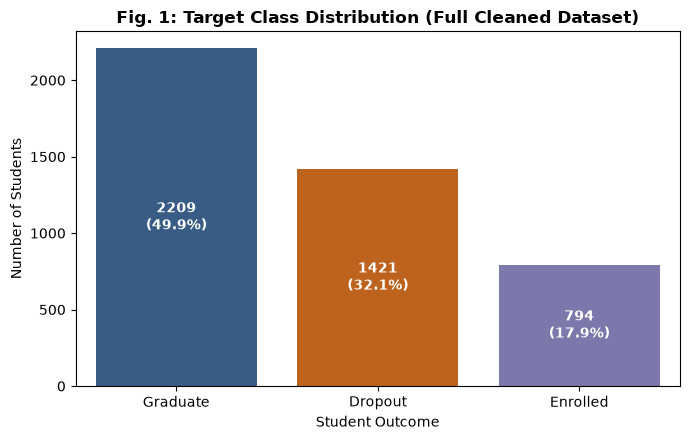

In [14]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(7, 4.5))
order = ["Graduate", "Dropout", "Enrolled"]
palette = {"Graduate": "#2b5c8f", "Dropout": "#d95f02", "Enrolled": "#7570b3"}

ax = sns.countplot(
    data=df_clean,
    x="academic_outcome" if "academic_outcome" in df_clean.columns else TARGET,
    order=order,
    palette=palette,
)

total = len(df_clean)
for p in ax.patches:
  h = p.get_height()
  pct = f"{100 * h / total:.1f}%"
  ax.annotate(
      f"{int(h)}\n({pct})",
      (p.get_x() + p.get_width() / 2.0, h / 2.0),
      ha="center",
      va="center",
      color="white",
      fontweight="bold",
      fontsize=10,
  )

plt.title(
    "Fig. 1: Target Class Distribution (Full Cleaned Dataset)",
    fontsize=12,
    fontweight="bold",
)
plt.xlabel("Student Outcome", fontsize=10)
plt.ylabel("Number of Students", fontsize=10)
plt.tight_layout()
plt.show()

Fig. 1 Takeaway: Fig. 1 reveals clear class imbalance (~50% Graduate, ~32% Dropout, and ~18% Enrolled). A naive baseline predicting "Graduate" across all instances achieves ~50% raw accuracy while having zero recall on Dropouts. This directly defends Decision D3: evaluating candidate models under Macro-F1 so minority class performance is weighted equally.

## Task 3: Train, validation and test split (60/20/20, stratified, seed 42)

**Why stratified:** the classes are imbalanced, so a plain random split could give one part noticeably fewer Enrolled or Dropout students. Stratifying keeps the class ratios the same in all three parts.

**Why random, not time-based:** each row is an independent student record with no timestamp, so there is no time order to respect.

**Why a validation split:** every choice (for example k in KNN) is made on validation. The test split is not touched until the single labelled test cell in Task 5.

**How:** split off 20% for test, then 25% of the remaining 80% for validation (0.25 × 0.80 = 0.20), giving 60/20/20. The row indices are saved to `artifacts/splits/` and every later cell calls `load_split()` instead of re-splitting.

In [15]:
# Task 3, cell 1: split row indices (stratified, seed 42) with checks that fail loudly
import os, json
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split

# SPLIT_DIR = Path("artifacts/splits") comes from the constants cell at the top

X_all = df_clean.drop(columns=[TARGET])
y_all = df_clean[TARGET]
idx = np.arange(len(df_clean))

idx_trval, idx_test = train_test_split(
    idx, test_size=0.20, stratify=y_all, random_state=SEED)
idx_train, idx_val = train_test_split(
    idx_trval, test_size=0.25, stratify=y_all.iloc[idx_trval], random_state=SEED)

# Check 1: no row is in two parts
assert len(np.intersect1d(idx_train, idx_val)) == 0, "train and validation overlap"
assert len(np.intersect1d(idx_train, idx_test)) == 0, "train and test overlap"
assert len(np.intersect1d(idx_val, idx_test)) == 0, "validation and test overlap"
# Check 2: every row is used exactly once
assert len(idx_train) + len(idx_val) + len(idx_test) == len(df_clean), "sizes do not add up"
assert np.array_equal(np.sort(np.concatenate([idx_train, idx_val, idx_test])), idx)
# Check 3: class proportions within 1 percentage point of the full data in every part
full_props = y_all.value_counts(normalize=True)
for name, part in [("train", idx_train), ("validation", idx_val), ("test", idx_test)]:
    diff = (y_all.iloc[part].value_counts(normalize=True) - full_props).abs().max()
    assert diff < 0.01, f"{name} class proportions differ by {diff:.3%}"

print("All split checks passed.")
print(f"train = {len(idx_train)}, validation = {len(idx_val)}, test = {len(idx_test)}, "
      f"total = {len(df_clean)}")

All split checks passed.
train = 2654, validation = 885, test = 885, total = 4424


In [16]:
# Task 3, cell 2: split table (rows and % of each class per part)
classes = sorted(y_all.unique(), key=str)
rows = []
for name, part in [("Train", idx_train), ("Validation", idx_val), ("Test", idx_test), ("All", idx)]:
    props = y_all.iloc[part].value_counts(normalize=True)
    row = {"Split": name, "Rows": len(part), "% of data": round(100 * len(part) / len(idx), 1)}
    for c in classes:
        row[f"% {c}"] = round(100 * props.get(c, 0.0), 1)
    rows.append(row)
split_table = pd.DataFrame(rows).set_index("Split")
print(f"Split table (stratified on {TARGET}, SEED = {SEED})")
split_table

Split table (stratified on academic_outcome, SEED = 42)


,Rows,% of data,% Dropout,% Enrolled,% Graduate
Split,,,,,
Train,2654,60.0,32.1,17.9,49.9
Validation,885,20.0,32.1,18.0,49.9
Test,885,20.0,32.1,18.0,49.9
All,4424,100.0,32.1,17.9,49.9


In [17]:
# Task 3, cell 3: save the indices once; on later runs, confirm they still match
os.makedirs(SPLIT_DIR, exist_ok=True)
paths = {name: os.path.join(SPLIT_DIR, f"idx_{name}.npy") for name in ["train", "val", "test"]}
meta_path = os.path.join(SPLIT_DIR, "split_meta.json")
current = {"train": idx_train, "val": idx_val, "test": idx_test}
meta = {"seed": SEED, "target": TARGET, "n_rows": int(len(df_clean)),
        "sizes": {k: int(len(v)) for k, v in current.items()}}

if all(os.path.exists(p) for p in paths.values()):
    for name, p in paths.items():
        assert np.array_equal(np.load(p), current[name]), (
            f"Saved {name} indices differ from this run. Did Task 1 cleaning change? "
            "Do not overwrite the frozen split without telling the whole group.")
    print("Saved split found and it matches this run exactly. Nothing overwritten.")
else:
    for name, p in paths.items():
        np.save(p, current[name])
    with open(meta_path, "w") as f:
        json.dump(meta, f, indent=2)
    print("Split saved to", SPLIT_DIR, "- commit these files.")

Saved split found and it matches this run exactly. Nothing overwritten.


In [18]:
# Task 3, cell 4: load_split() is the ONLY way later cells get data. Nothing re-splits.
def load_split(df=None, split_dir=SPLIT_DIR):
    # Returns X_train, y_train, X_val, y_val, X_test, y_test from the saved indices.
    df = df_clean if df is None else df
    with open(os.path.join(split_dir, "split_meta.json")) as f:
        meta = json.load(f)
    assert len(df) == meta["n_rows"], (
        f"df has {len(df)} rows but the split was saved for {meta['n_rows']}. "
        "Task 1 cleaning changed after the split was frozen.")
    out = []
    for name in ["train", "val", "test"]:
        part = np.load(os.path.join(split_dir, f"idx_{name}.npy"))
        out += [df.drop(columns=[meta["target"]]).iloc[part], df[meta["target"]].iloc[part]]
    return tuple(out)

X_train, y_train, X_val, y_val, X_test, y_test = load_split()
print("Loaded from disk:", X_train.shape, X_val.shape, X_test.shape)
# Reminder: X_test / y_test are not used until the single TEST EVALUATION cell in Task 5.

Loaded from disk: (2654, 36) (885, 36) (885, 36)


TASK 2b - After the data split

C:\Users\Pavle\AppData\Local\Temp\ipykernel_21808\3755719049.py:23: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(


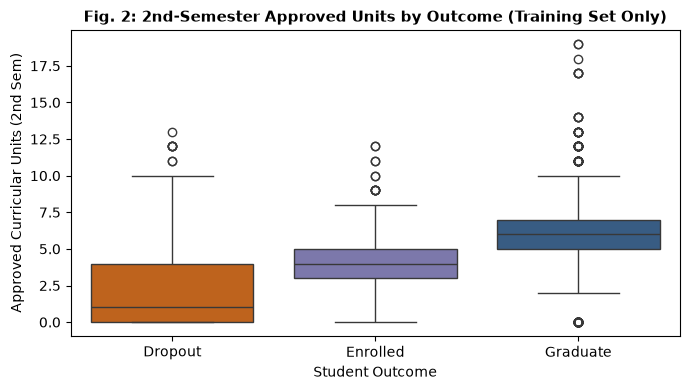

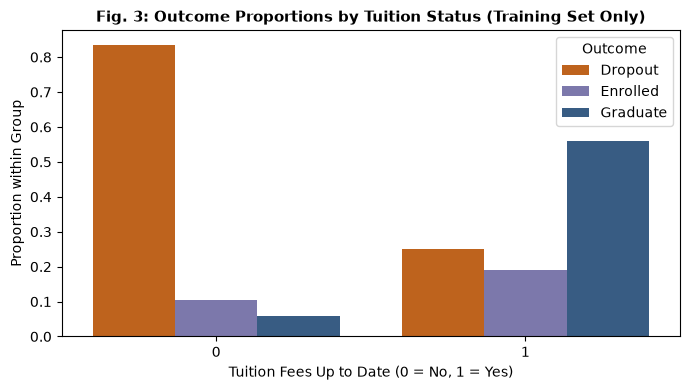

In [19]:
# Task 2b: Academic & Financial Signals (Training Set Only)
import matplotlib.pyplot as plt
import seaborn as sns

palette = {"Graduate": "#2b5c8f", "Dropout": "#d95f02", "Enrolled": "#7570b3"}
target_name = (
    TARGET
    if "TARGET" in locals()
    else (
        "academic_outcome"
        if "academic_outcome" in df_clean.columns
        else "AcademicOutcome"
    )
)

# 1. Call Member 3's load_split to get training rows strictly
X_train, y_train, X_val, y_val, X_test, y_test = load_split()
df_train = X_train.copy()
df_train[target_name] = y_train

# --- Fig. 2: Academic Progress (2nd Sem Approved Units) ---
plt.figure(figsize=(7, 4))
sns.boxplot(
    data=df_train,
    x=target_name,
    y="curricular_units_2nd_sem_approved",
    order=["Dropout", "Enrolled", "Graduate"],
    palette=palette,
)
plt.title(
    "Fig. 2: 2nd-Semester Approved Units by Outcome (Training Set Only)",
    fontsize=11,
    fontweight="bold",
)
plt.xlabel("Student Outcome", fontsize=10)
plt.ylabel("Approved Curricular Units (2nd Sem)", fontsize=10)
plt.tight_layout()
plt.show()

# --- Fig. 3: Financial Standing (Tuition Fees Up to Date) ---
tuition_prop = (
    df_train.groupby("tuition_fees_up_to_date")[target_name]
    .value_counts(normalize=True)
    .rename("proportion")
    .reset_index()
)

plt.figure(figsize=(7, 4))
sns.barplot(
    data=tuition_prop,
    x="tuition_fees_up_to_date",
    y="proportion",
    hue=target_name,
    hue_order=["Dropout", "Enrolled", "Graduate"],
    palette=palette,
)
plt.title(
    "Fig. 3: Outcome Proportions by Tuition Status (Training Set Only)",
    fontsize=11,
    fontweight="bold",
)
plt.xlabel("Tuition Fees Up to Date (0 = No, 1 = Yes)", fontsize=10)
plt.ylabel("Proportion within Group", fontsize=10)
plt.legend(title="Outcome")
plt.tight_layout()
plt.show()

Fig. 2 Takeaway: 2nd-semester approved units provide the strongest academic separation: dropouts have a median near 0–1 passed units, whereas graduates consistently complete ~5–6 units. This confirms academic progress by the end of Year 1 is the primary predictor of graduation (defending Decision D2).

Fig. 3 Takeaway: Administrative and financial standing represents a severe risk factor: students with unpaid tuition drop out at an overwhelming rate (>80%), highlighting financial delinquency as a key early-warning signal.

## Task 4: Preprocessing pipeline (shared by every baseline)

One `ColumnTransformer`, one branch per column type, fit on the **training split only**. Every model is wrapped with `make_model_pipeline()`, so all baselines get identical preprocessing and the comparison is fair.

| Branch | Columns | Steps | Why |
|---|---|---|---|
| `num` | numeric + ordinal | median imputer → standard scaler | Median is robust to outliers. KNN and SVM use distances and regularized logistic regression is scale-sensitive, so features need comparable scales. |
| `nom` | nominal codes (course, occupation, …) | most-frequent imputer → one-hot encoder | The Course, occupation etc. are categories, not quantities; scaling them as numbers would imply a false order. `handle_unknown="ignore"` stops an unseen category from crashing validation/test; `min_frequency=10` groups rare categories so they don't inflate the feature count. |
| `bin` | 0/1 flags | most-frequent imputer | Already 0/1, so no scaling needed. |

**Why an imputer when nothing is missing?** The handout asks us to justify missing-value handling, and the pipeline stays valid if the data changes. Median for numeric (robust), most-frequent for categories (a mean of codes means nothing).

`min_frequency` needs scikit-learn ≥ 1.1 and `sparse_output` needs ≥ 1.2, so `requirements.txt` has `scikit-learn>=1.3`.

In [20]:
# Task 4, cell 1: the shared preprocessor and make_model_pipeline()
import sklearn
from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

print("scikit-learn version:", sklearn.__version__)

# Every feature must be in exactly one list (lists come from Task 1)
all_listed = numeric_cols + ordinal_cols + nominal_cols + binary_cols
assert len(all_listed) == len(set(all_listed)), "a column appears in two lists"
assert set(all_listed) == set(X_train.columns), (
    f"missing from lists: {set(X_train.columns) - set(all_listed)}; "
    f"not in data: {set(all_listed) - set(X_train.columns)}")

num_pipe = Pipeline([("impute", SimpleImputer(strategy="median")),
                     ("scale", StandardScaler())])
nom_pipe = Pipeline([("impute", SimpleImputer(strategy="most_frequent")),
                     ("onehot", OneHotEncoder(handle_unknown="ignore",
                                              min_frequency=10,
                                              sparse_output=False))])
preprocessor = ColumnTransformer([
    ("num", num_pipe, numeric_cols + ordinal_cols),
    ("nom", nom_pipe, nominal_cols),
    ("bin", SimpleImputer(strategy="most_frequent"), binary_cols)])

def make_model_pipeline(estimator):
    # A fresh, unfitted copy of the preprocessor + the model. .fit(X_train, y_train) fits both on train only.
    return Pipeline([("prep", clone(preprocessor)), ("model", estimator)])

scikit-learn version: 1.9.1


In [21]:
# Task 4, cell 2: fit on TRAINING data only, then inspect
prep_check = clone(preprocessor).fit(X_train)          # fit: training rows only
Xt_train = prep_check.transform(X_train)
Xt_val = prep_check.transform(X_val)                   # transform only, never fit, on validation

n_features_before = X_train.shape[1]
n_features_after = Xt_train.shape[1]
feature_names = prep_check.get_feature_names_out()

print(f"Features before preprocessing: {n_features_before}")
print(f"Features after preprocessing:  {n_features_after}   <- Member 4 uses this in Table 1")
print("Train output shape:", Xt_train.shape, "| Validation output shape:", Xt_val.shape)
print("Per branch:", {name: len([f for f in feature_names if f.startswith(name + '__')])
                      for name in ["num", "nom", "bin"]})
print("Example feature names:", list(feature_names[:5]), "...", list(feature_names[-3:]))

Features before preprocessing: 36
Features after preprocessing:  124   <- Member 4 uses this in Table 1
Train output shape: (2654, 124) | Validation output shape: (885, 124)
Per branch: {'num': 19, 'nom': 97, 'bin': 8}
Example feature names: ['num__previous_qualification_grade', 'num__admission_grade', 'num__age_at_enrollment', 'num__curricular_units_1st_sem_credited', 'num__curricular_units_1st_sem_enrolled'] ... ['bin__gender', 'bin__scholarship_holder', 'bin__international']


In [22]:
# Task 4, cell 3: LEAKAGE CHECK - proves the preprocessor learned from training rows only
import glob

scaler = prep_check.named_transformers_["num"].named_steps["scale"]
scaled_cols = numeric_cols + ordinal_cols
train_means = X_train[scaled_cols].astype(float).mean().values
full_means = X_all[scaled_cols].astype(float).mean().values

# 1. Scaler means equal the TRAINING means ...
assert np.allclose(scaler.mean_, train_means), "scaler means are not the training means"
# 2. ... and differ from the full-data means (if they matched, it was fit on everything)
assert not np.allclose(scaler.mean_, full_means), "scaler means match full data: possible leakage"
# 3. The scaler saw exactly the number of training rows
assert np.all(scaler.n_samples_seen_ == len(X_train)), "scaler saw a different number of rows"
print(f"Scaler fit on {len(X_train)} training rows (full data has {len(X_all)}).")
print(f"Largest gap between scaler means and full-data means: "
      f"{np.abs(scaler.mean_ - full_means).max():.4f} (non-zero, as expected)")

# 4. List every fit( / fit_transform( call in the saved notebook so we can confirm each uses training data
nb_files = glob.glob("DS3000_Project_Group*.ipynb")
if nb_files:
    with open(nb_files[0], encoding="utf-8") as f:
        nb = json.load(f)
    print(f"\nEvery fit call in {nb_files[0]} (save the notebook first so this is current):")
    for i, cell in enumerate(nb["cells"]):
        if cell["cell_type"] != "code":
            continue
        for line in "".join(cell["source"]).splitlines():
            is_fit = "fit(" in line or "fit_transform(" in line
            if is_fit and not line.strip().startswith("#") and '"fit("' not in line:
                print(f"  cell {i}: {line.strip()}")
    print("Confirm by eye: each call above receives X_train / y_train only.")
print("\nLeakage checks passed.")

Scaler fit on 2654 training rows (full data has 4424).
Largest gap between scaler means and full-data means: 0.2137 (non-zero, as expected)

Every fit call in DS3000_Project_Group03.ipynb (save the notebook first so this is current):
  cell 43: prep_check = clone(preprocessor).fit(X_train)          # fit: training rows only
Confirm by eye: each call above receives X_train / y_train only.

Leakage checks passed.


## Task 5: Baseline models

TODO: Train the baseline models under the D6 fair-comparison rules.

## Task 6: Comparison table

TODO: Tabulate validation metrics (D3) for all models and save to artifacts/results/.

## Task 7: Stage 1 conclusion and unresolved risk

TODO: Summarise Stage 1 findings and the main unresolved risk.

## Contribution log

| Member | Tasks | Notes |
|---|---|---|
|  |  |  |

## AI-use disclosure and citations

- **Dataset citation:** TODO: copy the citation from the OpenML (https://www.openml.org/d/46960) or UCI dataset page.
- **Libraries used:** TODO: list libraries and versions (pandas, numpy, scikit-learn, matplotlib, seaborn).
- **Generative-AI assistance:** TODO: describe any generative-AI use per course policy (tool, what it was used for, how outputs were checked).

## Reproducibility

- **Environment:** TODO: Python version and `pip install -r requirements.txt` in a fresh `.venv`.
- **Run order:** TODO: restart kernel, then Run All from top to bottom.
- **Commit hash:** TODO: record the final commit hash.
- **Smoke test:** TODO: add a smoke-test cell that checks the saved splits reload and key outputs exist.